# 01. PyTorch Workflow


In [1]:
what_were_covering = {1: "data (prepare and load)",
    2: "build model",
    3: "fitting the model to data (training)",
    4: "making predictions and evaluating a model (inference)",
    5: "saving and loading a model",
    6: "putting it all together"
}
what_were_covering

{1: 'data (prepare and load)',
 2: 'build model',
 3: 'fitting the model to data (training)',
 4: 'making predictions and evaluating a model (inference)',
 5: 'saving and loading a model',
 6: 'putting it all together'}

In [2]:
import torch
from torch import nn # nn contains all PyTorch's building blocks for neural networks
import matplotlib.pyplot as plt

torch.__version__

'2.12.1+cu130'

## 1. Data (preparing an loading)

<div style="font-size: 15px;">

Data can be anything in ML
* Excel spreadsheet
* Images of any kind
* Videos
* Audio like songs or podcast
* DNA
* Text

Machine learning is a game of two parts:
1. Get data into a numerical representation.
2. Build a model to learn patterns in that numerical representation.

Let's create some *known* data using the linear regression formula
We'll use a linear regression formula to make a straight line with *known* **parameters**.

</div>

In [3]:
# Create *known* parameters

weight = 0.7
bias = 0.3

# Create

start = 0
end = 1
step = 0.02

X = torch.arange(start, end, step).unsqueeze(dim=1)
y = weight * X + bias

X[:10], y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [4]:
len(X), len(y)

(50, 50)

### Splitting data into training and test sets

In [5]:
# Create a train/test split
train_split = int(.8 * len(X))
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

### Visualizing data

In [6]:
def plot_predictions(train_data = X_train,
                     train_labels = y_train,
                     test_data = X_test,
                     test_labels = y_test,
                     predictions = None):
    """_summary_
    Plots training data, test data and compares predictions.
    """
    
    plt.figure(figsize=(10, 7))
    
    # Plot trazining data in blue
    
    plt.scatter(train_data, train_labels, c = "b", s = 4, label = "Training data")
    
    # Plot test data in green
    
    plt.scatter(test_data, test_labels, c = "g", s = 4, label = "Testing data")
    
    # Are there predictions?
    
    if predictions is not None:
        # Plot the predictions if they exist
        plt.scatter(test_data, predictions, c = "r", s = 4, label = "Predictions")
        
    # Show the legend
    plt.legend(prop = {"size" : 14});

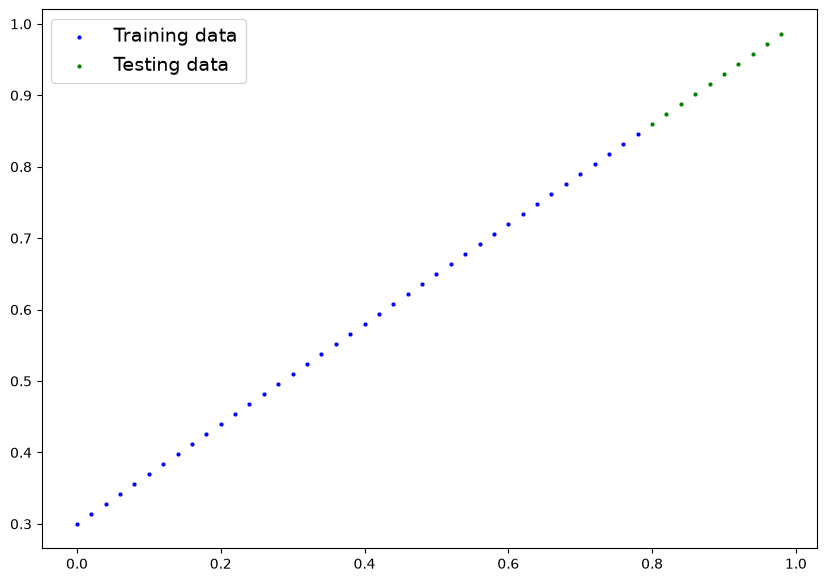

In [7]:
plot_predictions();

## 2. Build model

<div style="font-size: 15px">

What this model does:
* Start with random values (weight & bias)
* Look at training data and adjust the random values to better represent (or get closer to) the ideal values (the weight & bias values we used to create the data)

How does it do so:

Through 2 main algorithms:
1. Gradient descent
2. Backpropagation`

</div>

In [8]:
from numpy import dtype
# Create a linear regression model class
class LinearRegressionModel(nn.Module): # <- almost everything in PyTorch inherits from nn.Module
    def __init__(self):
        super().__init__()
        # Initialize model parameters
        self.weights = nn.Parameter(torch.randn(1,
                                                requires_grad = True,
                                                dtype = torch.float))
        self.bias = nn.Parameter(torch.rand(1,
                                            requires_grad = True,
                                            dtype = torch.float))
        # forward() defines the computation in the model
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.weights * x + self.bias # this is the linear regression formula

### PyTorch model building essentials

<div style="font-size: 15px">

* torch.nn - contains all of the buildings for computational graphs (a neural network can be considered a computational graph)
* torch.nn.Parameters - what parameters should our model try and learn, often a PyTorch layer from torch.nn will set these for us
* torch.nn.Module - The base class for all neural network modules, if you subclass it, you should overwrite forward()
* torch.optim - this is where the optimizers in PyTorch live, they will help with gradient descent
* def forward() - all nn.Module subclasses require you to overwrite forward(), this method defines what happens in the forward computation

</div>

### Checking the contents of our PyTorch model

we can check our model parameters or what's inside our model using .parameters()

In [9]:
# Create a random seed
torch.manual_seed(42)

# Create an instance of the model (this is a subclass of nn.module)
model_0 = LinearRegressionModel()

# Check out the parametes
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.3904], requires_grad=True)]

In [10]:
# List named parameters
model_0.state_dict()

OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.3904]))])

### Making prediction using `torch.inference_mode()`

<div style="font-size: 15px">

To check our model's predictive power, let's see how well it predicts `y_test` based on `X_test`.

When we pass data through our model, it's going to run it through thee `forward()` method.

</div>

In [11]:
# Make predictions with model
with torch.inference_mode():
    y_preds = model_0(X_test)
    
y_preds, y_test

(tensor([[0.6598],
         [0.6665],
         [0.6733],
         [0.6800],
         [0.6867],
         [0.6935],
         [0.7002],
         [0.7069],
         [0.7137],
         [0.7204]]),
 tensor([[0.8600],
         [0.8740],
         [0.8880],
         [0.9020],
         [0.9160],
         [0.9300],
         [0.9440],
         [0.9580],
         [0.9720],
         [0.9860]]))

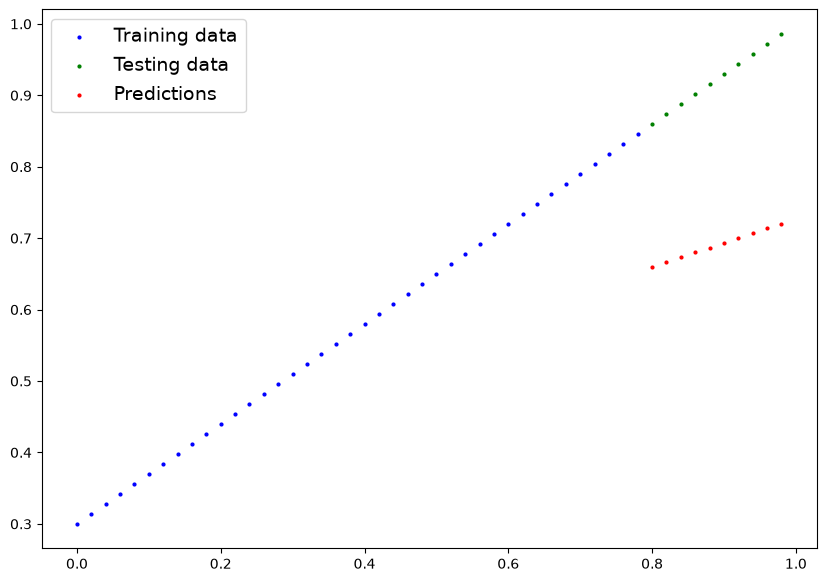

In [12]:
plot_predictions(predictions = y_preds)

## 3. Train model

<div style="font-size: 15px">

The whole idea of **training** is for a model to move from some ***unknown*** parameters(may be random) to some ***known*** parameters

Or in other words, from a poor representation of the data to a better representation of the data

One way to measure how poor or how wrong your models predictions are is to use a loss function.

* **Note:** Loss function may also be called cost function or criterion in different areas. For our case, we're goint to refer to it as a loss function.

Things we need to train:

* **Loss Function:** A function to measure how wrong your model's predictions are to the ideal outpus, lower is better
* **Optimizer:** Takes into account the loss of a model and adjusts the model's parameters(e.g. weight & bias)
    * Inside the optimizer you'll often have to set two parameters:
        * `params` - the model parameters you'd like to optimize, for example `params=model_0.parameters()`
        * `lr` (learning rate) - the learning rate is a hyperparameter that defines how big/small the optimizer changes the parameters with each step (a small `lr` results in small changes, a large `lr` results in large changes)

And specifically for PyTorch, we need:
* A training loop
* A testing loop

</div>

In [13]:
list(model_0.parameters()), model_0.state_dict()

([Parameter containing:
  tensor([0.3367], requires_grad=True),
  Parameter containing:
  tensor([0.3904], requires_grad=True)],
 OrderedDict([('weights', tensor([0.3367])), ('bias', tensor([0.3904]))]))

In [14]:
# Setup a loss function

loss_fn = nn.L1Loss()

# Setup an optimizer (Stochastic Gradient Descent)

optimizer = torch.optim.SGD(params = model_0.parameters(),
                            lr = 0.01) # lr = learning rate = possibly the most important hyperparameter you can set

<div style = "font-size: 15px">

**Q:** Which loss function and optimizer should I use?

**A:** This willbe problem specific. But with experience, you'll get an idea of what works and what doesn't with your particular problem set.

For example, for a regression problem (like ours), a loss function of `nn.L1Loss()` and an optimizer like `torch.optim.SGD()` will suffice.

But for a classification problem like classifying whether a photo is a dog or a cat, you'll likely waant to use a loss function of `nn.BCELoss()` (Binary Cross Entropy Loss)

</div>

### Building a training loop (and a testing loop) in PyTorch

<div style = "font-size: 15px">

A couple of things we need in a training loop:

0. Loop through the data
1. Forward pass (this involves data moving through our model's `forward()` functions) to make predictions on data - also called forward propagation
2. Calculate the loss (compare forward pass predictions to ground truth labels)
3. Optimizer zero grad
4. Loss backward - move backwards through the network to calculate the gradients of each of the parameters of our model with respet to the loss (**backpropagation**)
5. Optimizer step - use the optimizer to adjust our model's parameters to try and improve the loss (**gradient descent**)

</div>

In [18]:
torch.manual_seed(42)

# An epoch is one loop through the data... (this is a hyperparameter because we've set it ourselves)

epochs = 100

### Training
# 0. Loop through the data
for epoch in range(epochs):
    # Set the model to training mode
    model_0.train() # train mode in PyTorch sets all paramemters which require gradient to require gradient

    # 1. Forward pass
    y_pred = model_0(X_train)

    # 2. Calculate the loss
    loss = loss_fn(y_pred, y_train)
    # print(f"Loss: {loss}")
    
    # 3. Optimizer zero grad
    optimizer.zero_grad()
    
    # 4. Perform backpropagation on the loss with respect to the parameters of the model
    loss.backward()
    
    # 5. Step the optimizer (perform gradient descent)
    optimizer.step() # by default how the optimizer changes will accumulate through the loop. So, we have to zero them above in step 3 for the next iteration of the loop

    # Testing
    model_0.eval() # turns off different settings in the model not needed for evaluation/testing
    with torch.inference_mode(): # turns off gradient tracking & a couple more things behind the scenes
        # 1. Do the forward pass
        test_pred = model_0(X_test)
        
        # 2. Calculate the loss
        test_loss = loss_fn(test_pred, y_test)
        
    # Printing out what's happening
    if epoch % 10 == 0:
        print(f"Epoch: {epoch} | Loss: {loss} | Test loss: {test_loss}")
    
        # Print out model state_dict()
        print(model_0.state_dict())

Epoch: 0 | Loss: 0.034646838903427124 | Test loss: 0.08051808178424835
OrderedDict({'weights': tensor([0.5293]), 'bias': tensor([0.3714])})
Epoch: 10 | Loss: 0.031217509880661964 | Test loss: 0.0722455382347107
OrderedDict({'weights': tensor([0.5464]), 'bias': tensor([0.3644])})
Epoch: 20 | Loss: 0.027778705582022667 | Test loss: 0.06397300213575363
OrderedDict({'weights': tensor([0.5636]), 'bias': tensor([0.3574])})
Epoch: 30 | Loss: 0.024344902485609055 | Test loss: 0.05638733506202698
OrderedDict({'weights': tensor([0.5805]), 'bias': tensor([0.3499])})
Epoch: 40 | Loss: 0.020913895219564438 | Test loss: 0.04811479523777962
OrderedDict({'weights': tensor([0.5977]), 'bias': tensor([0.3429])})
Epoch: 50 | Loss: 0.017475087195634842 | Test loss: 0.03984225541353226
OrderedDict({'weights': tensor([0.6148]), 'bias': tensor([0.3359])})
Epoch: 60 | Loss: 0.014042967930436134 | Test loss: 0.0322565920650959
OrderedDict({'weights': tensor([0.6318]), 'bias': tensor([0.3284])})
Epoch: 70 | Loss

In [19]:
with torch.inference_mode():
    y_preds_new = model_0(X_test)

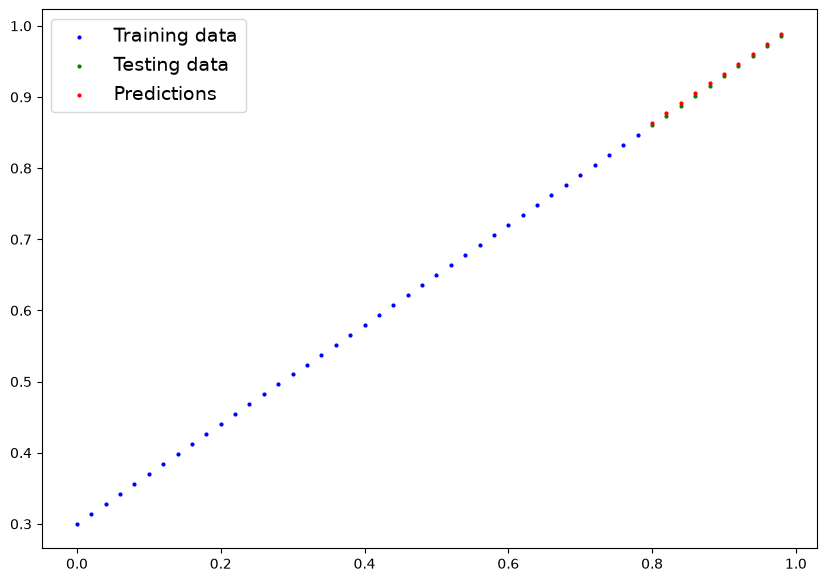

In [20]:
plot_predictions(predictions=y_preds_new)